In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/Pdrsmth/ibm-developer-survey-capstone/main/survey_data_updated.csv"
df = pd.read_csv(url)
print(df.shape)
df.head(3)


(18845, 114)


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor's degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
1,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
2,10,I am a developer by profession,35-44 years old,"Independent contractor, freelancer, or self-em...",Remote,Apples,Bootstrapping a business,"Master's degree (M.A., M.S., M.Eng., MBA, etc.)",On the job training;Other online resources (e....,Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN


In [2]:
print("duplikat:", df.duplicated().sum())
print()
print("missing values terbanyak:")
print(df.isnull().sum().sort_values(ascending=False).head(10))


duplikat: 0

missing values terbanyak:
AINextMuch less integrated       18492
AINextLess integrated            18093
AINextNo change                  14468
AINextMuch more integrated       13676
EmbeddedAdmired                  13064
EmbeddedWantToWorkWith           12932
EmbeddedHaveWorkedWith           11943
AIToolNot interested in Using    10067
AINextMore integrated             9816
ConvertedCompYearly               9295
dtype: int64


In [3]:
print("total responden:", df.shape[0])
print("\ntop 10 negara:")
print(df['Country'].value_counts().head(10))
print("\neducation:")
print(df['EdLevel'].value_counts().head(5))


total responden: 18845

top 10 negara:
Country
United States of America                                3441
Germany                                                 1339
India                                                   1316
United Kingdom of Great Britain and Northern Ireland    1053
Ukraine                                                  931
Canada                                                   661
France                                                   598
Brazil                                                   587
Poland                                                   494
Netherlands                                              480
Name: count, dtype: int64

education:
EdLevel
Bachelor's degree (B.A., B.S., B.Eng., etc.)                                          8629
Master's degree (M.A., M.S., M.Eng., MBA, etc.)                                       5000
Some college/university study without earning a degree                                2456
Secondary school (e.g. A

/tmp/ipykernel_592/316788888.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_lang.values, y=top_lang.index, palette='viridis')


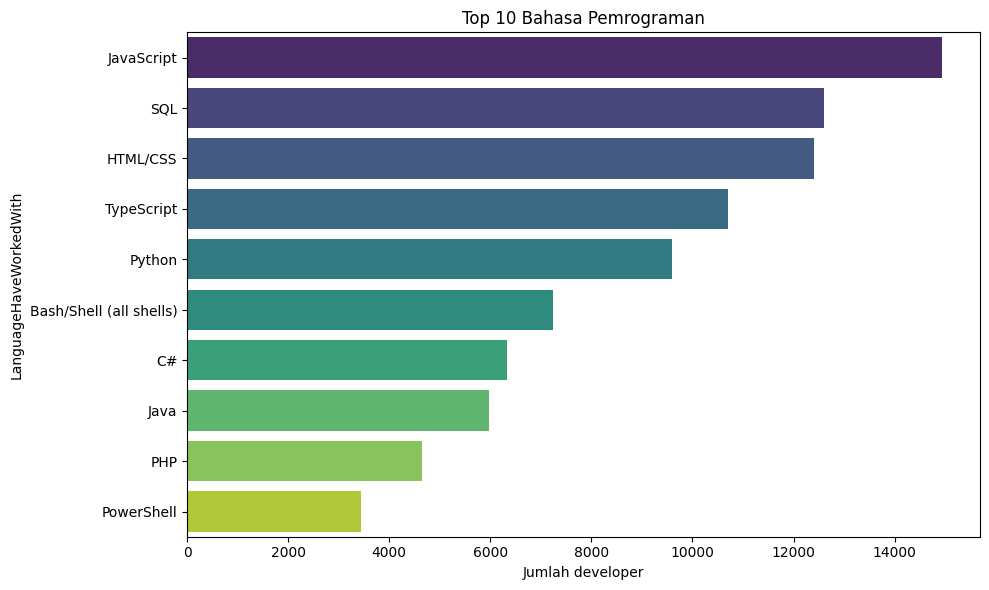

In [4]:
lang = df['LanguageHaveWorkedWith'].dropna().str.split(';').explode()
top_lang = lang.value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_lang.values, y=top_lang.index, palette='viridis')
plt.xlabel('Jumlah developer')
plt.title('Top 10 Bahasa Pemrograman')
plt.tight_layout()
plt.show()


/tmp/ipykernel_592/1532153693.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_db.values, y=top_db.index, palette='magma')


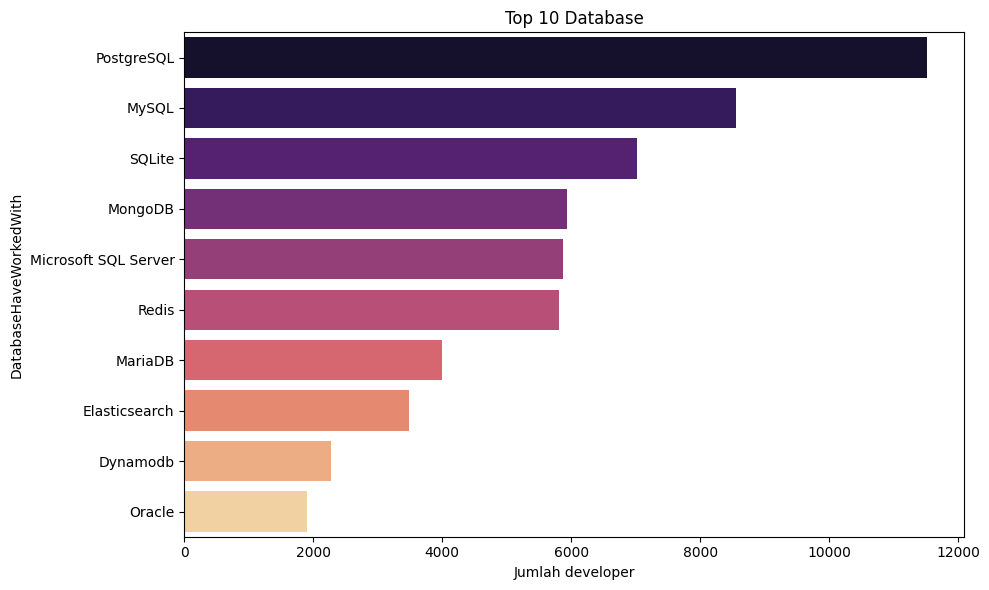

In [5]:
db = df['DatabaseHaveWorkedWith'].dropna().str.split(';').explode()
top_db = db.value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_db.values, y=top_db.index, palette='magma')
plt.xlabel('Jumlah developer')
plt.title('Top 10 Database')
plt.tight_layout()
plt.show()


/tmp/ipykernel_592/1479320769.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sal.values, y=sal.index, palette='coolwarm')


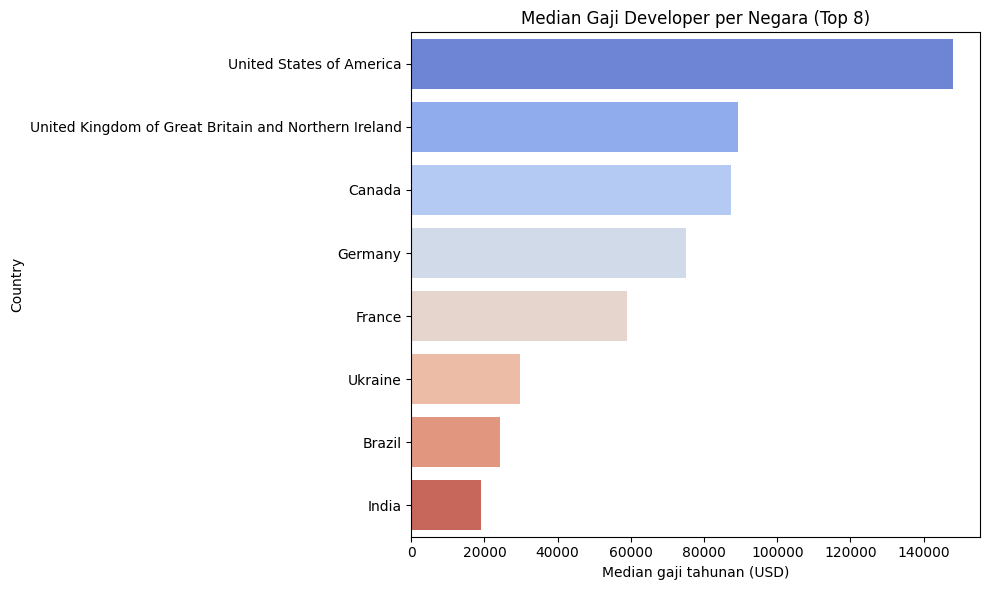

In [6]:
top_countries = df['Country'].value_counts().head(8).index
sal = df[df['Country'].isin(top_countries)].groupby('Country')['ConvertedCompYearly'].median().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=sal.values, y=sal.index, palette='coolwarm')
plt.xlabel('Median gaji tahunan (USD)')
plt.title('Median Gaji Developer per Negara (Top 8)')
plt.tight_layout()
plt.show()


/tmp/ipykernel_592/1489972117.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_ai.values, y=top_ai.index, palette='rocket')


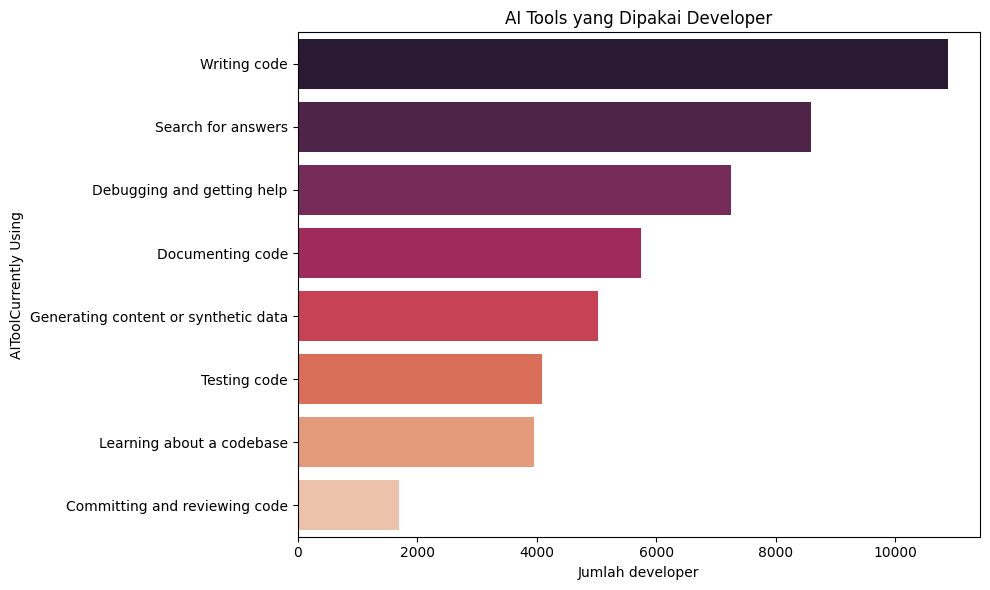

In [7]:
ai = df['AIToolCurrently Using'].dropna().str.split(';').explode()
top_ai = ai.value_counts().head(8)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_ai.values, y=top_ai.index, palette='rocket')
plt.xlabel('Jumlah developer')
plt.title('AI Tools yang Dipakai Developer')
plt.tight_layout()
plt.show()
